# Feature Engineering
##### ¿Qué variables vamos a utilizar para representar a cada cliente?

### 0. Librerias

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### 1. Carga de Datos

In [5]:
ruta = "../data/raw/online_retail_II.xlsx"

df_2009_2010 = pd.read_excel(ruta,  sheet_name="Year 2009-2010")
df_2010_2011 = pd.read_excel(ruta, sheet_name="Year 2010-2011")

df = pd.concat([df_2009_2010, df_2010_2011], ignore_index=True)

clientes = df[
    (~df["Invoice"].astype(str).str.startswith("C")) &
    (df["Customer ID"].notna()) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

clientes["TotalPrice"] = clientes["Quantity"] * clientes["Price"]

### 2. Construcción RFM

In [8]:
fecha_referencia = clientes["InvoiceDate"].max()

rfm = (
    clientes.groupby("Customer ID")
    .agg(
        recencia=(
            "InvoiceDate",
            lambda x: (fecha_referencia - x.max()).days
        ),
        frecuencia=("Invoice", "nunique"),
        gasto=("TotalPrice", "sum")
    )
)

rfm.describe()

,recencia,frecuencia,gasto
count,5878.000000,5878.000000,5878.000000
mean,200.331916,6.289384,3018.616737
std,209.338707,13.009406,14737.731040
min,0.000000,1.000000,2.950000
25%,25.000000,1.000000,348.762500
50%,95.000000,3.000000,898.915000
75%,379.000000,7.000000,2307.090000
max,738.000000,398.000000,608821.650000


Comprobar la distribución del rfm:

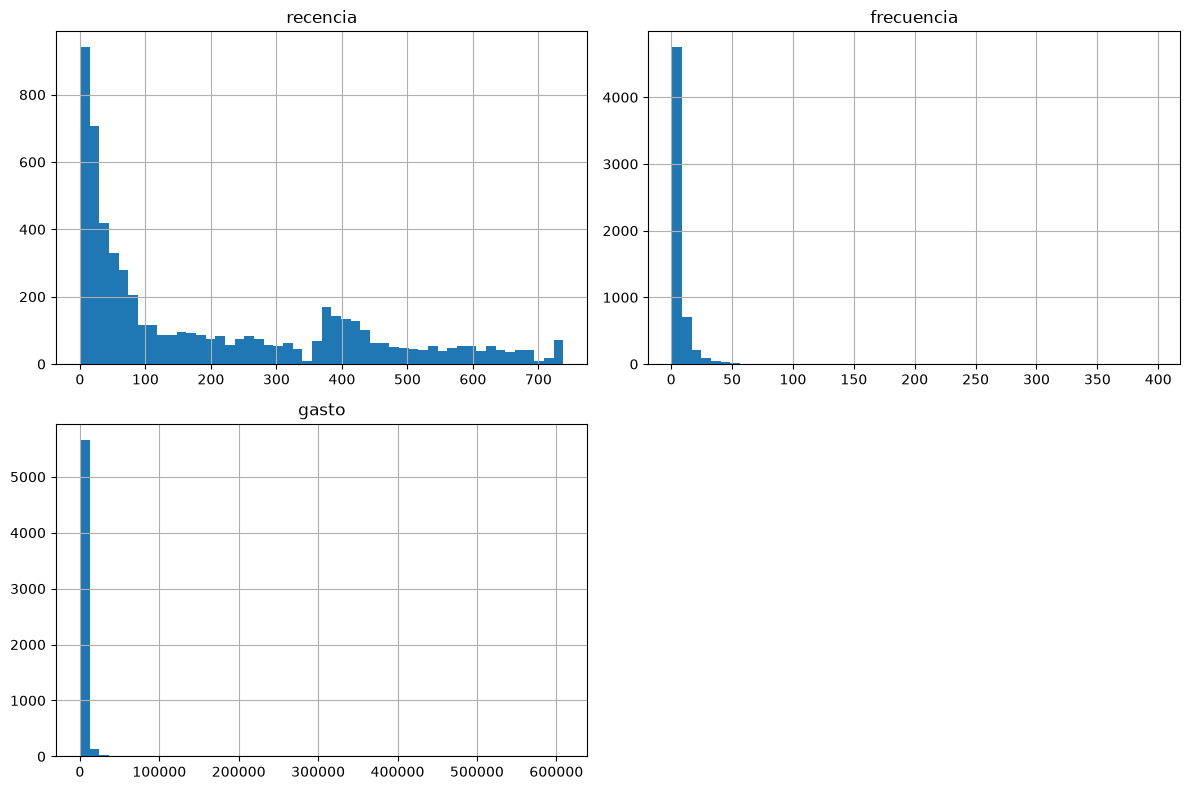

In [11]:
rfm.hist(
    bins=50,
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

Como frecuencia y gasto están muy sesgados, podemos aplicar una transformación logarítmica para reducir la influencia desproporcionada de losclientes extremos

In [13]:
rfm["frecuencia_log"] = np.log1p(rfm["frecuencia"])
rfm["gasto_log"] = np.log1p(rfm["gasto"])

rfm[["frecuencia", "frecuencia_log", "gasto", "gasto_log"]].describe()

,frecuencia,frecuencia_log,gasto,gasto_log
count,5878.000000,5878.000000,5878.000000,5878.000000
mean,6.289384,1.549588,3018.616737,6.836550
std,13.009406,0.809447,14737.731040,1.387864
min,1.000000,0.693147,2.950000,1.373716
25%,1.000000,0.693147,348.762500,5.857254
50%,3.000000,1.386294,898.915000,6.802300
75%,7.000000,2.079442,2307.090000,7.744175
max,398.000000,5.988961,608821.650000,13.319282


Añadimos algunas variables de comportamiento. En el clustering empezaremos con las variables rfm, despúes comprobaremos si las variables productos_distintos y unidades mejoran el clustering

In [15]:
perfil_extra = (
    clientes.groupby("Customer ID")
    .agg(
        productos_distintos=("StockCode", "nunique"),
        unidades=("Quantity", "sum")
    )
)
features_clientes = rfm.join(perfil_extra)

features_clientes.head()

,recencia,frecuencia,gasto,frecuencia_log,gasto_log,productos_distintos,unidades
Customer ID,,,,,,,
12346.0,325,12,77556.46,2.564949,11.258774,27,74285
12347.0,1,8,5633.32,2.197225,8.636632,126,3286
12348.0,74,5,2019.40,1.791759,7.611051,25,2714
12349.0,18,4,4428.69,1.609438,8.396085,138,1624
12350.0,309,1,334.40,0.693147,5.815324,17,197


 ### 3. Distribución de las variables

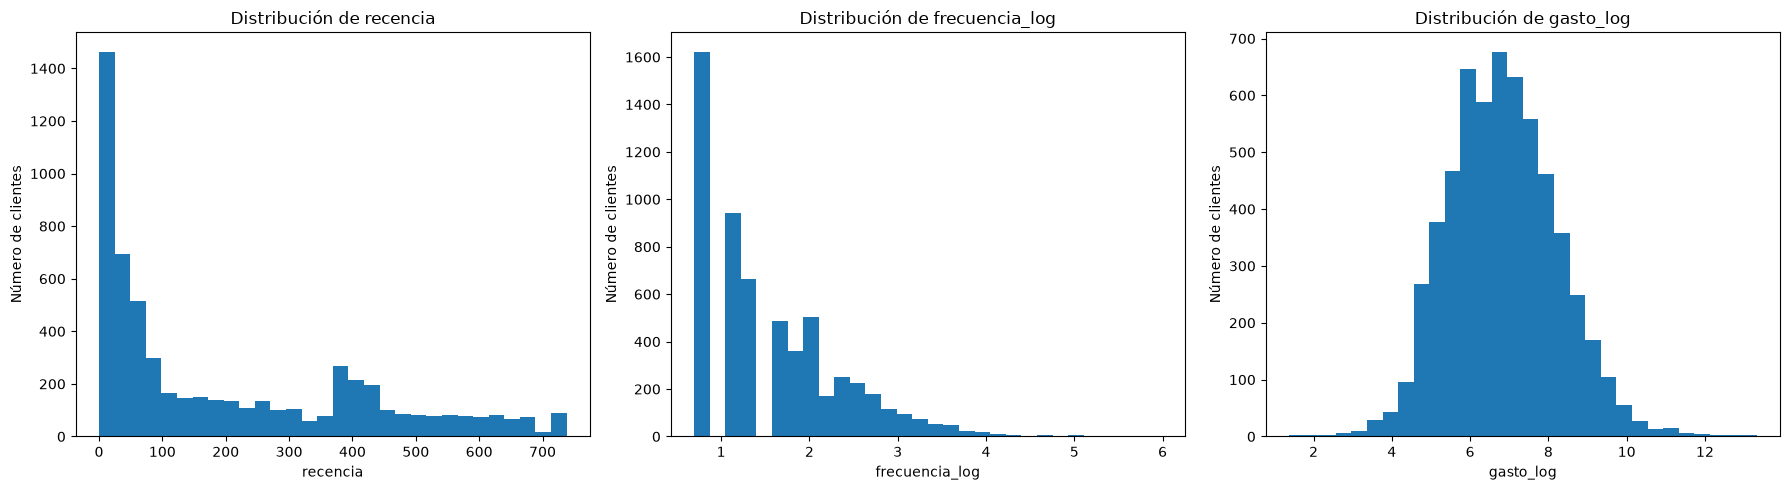

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, variable in zip(axes, variables_rfm):
    ax.hist(features_clientes[variable], bins=30)
    ax.set_title(f"Distribución de {variable}")
    ax.set_xlabel(variable)
    ax.set_ylabel("Número de clientes")

plt.tight_layout()
plt.show()

Comparamos las distribuciones obtenidas antes y después de apicar la disribución logarítmica.

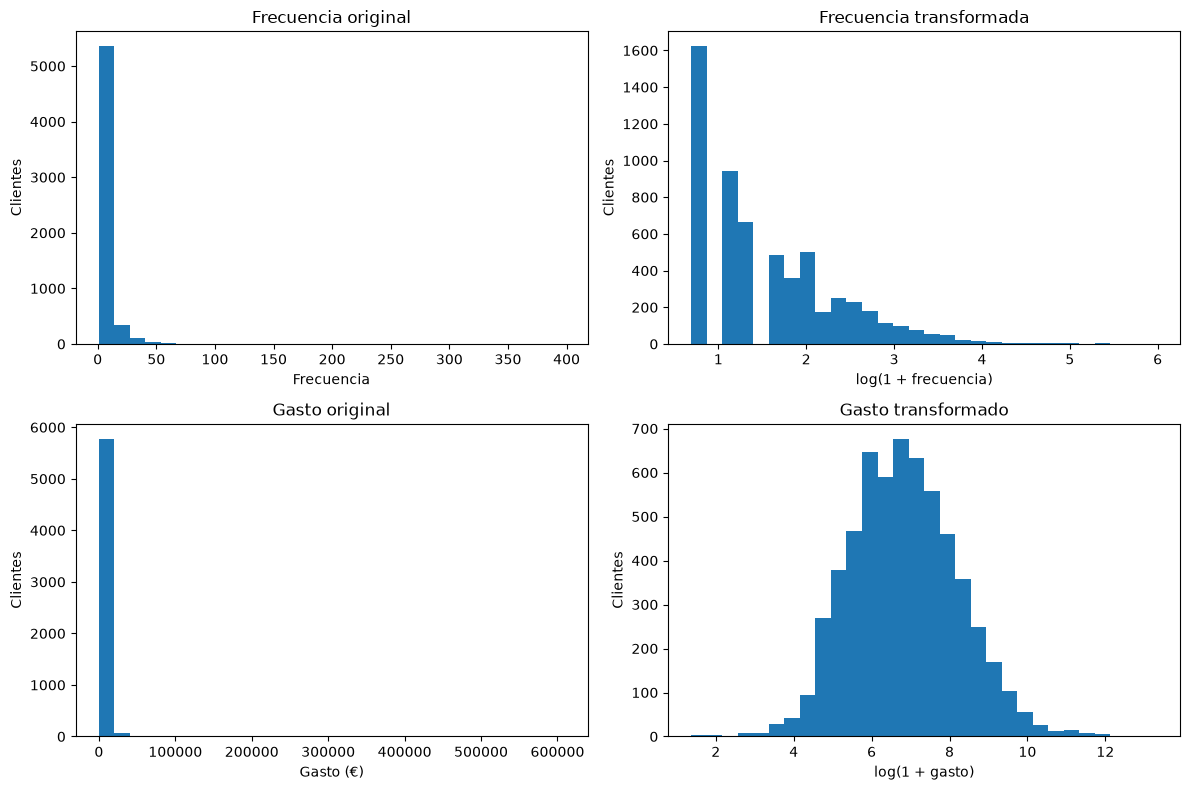

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(features_clientes["frecuencia"], bins=30)
axes[0, 0].set_title("Frecuencia original")
axes[0, 0].set_xlabel("Frecuencia")
axes[0, 0].set_ylabel("Clientes")

axes[0, 1].hist(features_clientes["frecuencia_log"], bins=30)
axes[0, 1].set_title("Frecuencia transformada")
axes[0, 1].set_xlabel("log(1 + frecuencia)")
axes[0, 1].set_ylabel("Clientes")

axes[1, 0].hist(features_clientes["gasto"], bins=30)
axes[1, 0].set_title("Gasto original")
axes[1, 0].set_xlabel("Gasto (€)")
axes[1, 0].set_ylabel("Clientes")

axes[1, 1].hist(features_clientes["gasto_log"], bins=30)
axes[1, 1].set_title("Gasto transformado")
axes[1, 1].set_xlabel("log(1 + gasto)")
axes[1, 1].set_ylabel("Clientes")

plt.tight_layout()
plt.show()

Ahora tenemos distribuciones mucho más manejables

### 4. Selección de variables para el clustering

Para nuestro primer modelo de segmentación utilizaremos las variables rfm, porque representan tres dimensiones muy interpretables del comportamiento (Recency, Frequency, Monetary), y es muy utilizado en análisis de clientes porque convierte el comportamiento transaccional en variables directamente interpretables.

Crear matriz X - matriz de características para clustering

In [29]:
X_rfm = features_clientes[variables_rfm].copy()

X_rfm.head()

# Como las escalas son diferentes, estandarizamos los datos:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_rfm_scaled = scaler.fit_transform(X_rfm)
X_rfm_scaled[:5]

X_rfm_scaled.mean(axis=0)


array([-4.23086011e-17,  2.38136984e-16, -4.35174183e-16])

### 5. ¿Cuántos Clusters necesitamos?
Utilizamos dos métodos:
- Elbow Method → observa cómo disminuye la variabilidad interna al aumentar k.
- Silhouette Score → mide qué tan bien separados están los grupos.

##### ELBOW METHOD

In [32]:
# Probamos distintos números de clusters por ejemplo de 1 a 10 y calculamos la inercia para cada uno:

inercia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_rfm_scaled)
    
    inercia.append(kmeans.inertia_)

Como añadir más clusters disminuye la varianza interna de cada grupo, buscamos un punto de "codo" donde añadir más clusters empieza a aportar mejoras mucho menores.

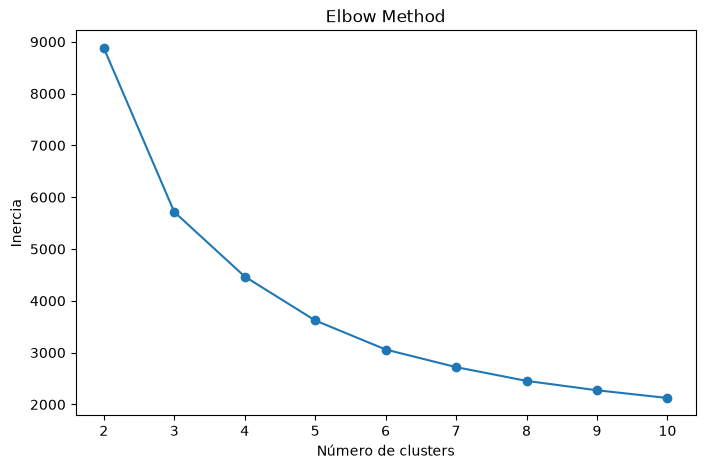

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inercia, marker="o")

plt.xlabel("Número de clusters")
plt.ylabel("Inercia")
plt.title("Elbow Method")

plt.show()

 ##### Silhouette Score

- Valores cercanos a 1 → grupos bien separados
- Valores alrededor de 0 → grupos bastante solapados
- Valores negativos → algunos clientes podrían estar mejor asignados a otro grupo.

In [ ]:
silhouette_scores = []

# Entrenamos el modelo
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    #asigna cada cliente a un cluster
    etiquetas = kmeans.fit_predict(X_rfm_scaled)
    
    #evalua la calidad de esa separación
    score = silhouette_score(X_rfm_scaled, etiquetas)
    
    silhouette_scores.append(score)

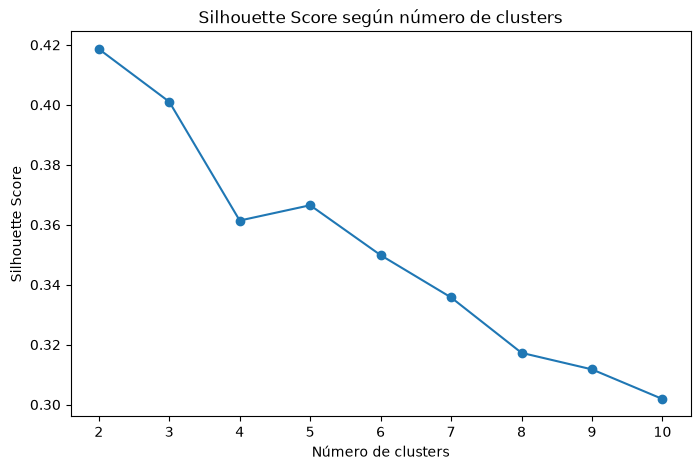

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_scores, marker="o")

plt.xlabel("Número de clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score según número de clusters")

plt.show()

Silhouette favorece k=2 y Elbow sugiere aproximadamente k=4-5. Vamos a crear clusters candidatos:

In [38]:
resultados_clusters = {}

for k in [2, 3, 4, 5]:
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    etiquetas = kmeans.fit_predict(X_rfm_scaled)
    
    resultados_clusters[k] = etiquetas

In [39]:
# Vemos el tamaño de cada cluster y el porcentaje de clientes que representa:
for k, etiquetas in resultados_clusters.items():
    
    print(f"\nK = {k}")
    
    valores, conteos = np.unique(etiquetas, return_counts=True)
    
    for cluster, cantidad in zip(valores, conteos):
        porcentaje = cantidad / len(etiquetas) * 100
        print(f"Cluster {cluster}: {cantidad} clientes ({porcentaje:.1f}%)")


K = 2
Cluster 0: 2674 clientes (45.5%)
Cluster 1: 3204 clientes (54.5%)

K = 3
Cluster 0: 1838 clientes (31.3%)
Cluster 1: 1689 clientes (28.7%)
Cluster 2: 2351 clientes (40.0%)

K = 4
Cluster 0: 1638 clientes (27.9%)
Cluster 1: 1384 clientes (23.5%)
Cluster 2: 1891 clientes (32.2%)
Cluster 3: 965 clientes (16.4%)

K = 5
Cluster 0: 1349 clientes (22.9%)
Cluster 1: 911 clientes (15.5%)
Cluster 2: 1688 clientes (28.7%)
Cluster 3: 850 clientes (14.5%)
Cluster 4: 1080 clientes (18.4%)
